# 09 · Field statistics of TNG50-4

The statistics of notebook 08 on the cells of a simulation, TNG50-4 snapshot 25: the same path (`field_statistics`:
every cell deposits its number of particles $n_X V$ at its generating point on a mesh, PCS and interlaced), the same bins
and figures, without an analytic expectation. The fields are the overdensities of the total gas and of the species of the
lines (`LINE_IDS`): H I, Si III and Si II. Real space, and redshift space along each axis: the generating points moved by
their peculiar velocity along the line of sight, $v_\parallel/(aH)$, wrapped into the box, so that the anisotropic figures
of 08 have a counterpart. The three axes $x$, $y$, $z$ as the line of sight are the ensemble (points with error bars:
the mean over the three and its error), correlated through the same gas.

The BAO scale of the simulation's cosmology, $r_d \simeq 147$ cMpc, is larger than half the box ($L/2 = 25.8$ cMpc): a
periodic box holds only its images, $\xi_{\rm box}(\mathbf r) = \sum_{\mathbf n}\xi(\lvert\mathbf r + \mathbf nL\rvert)$,
marked where they fall.

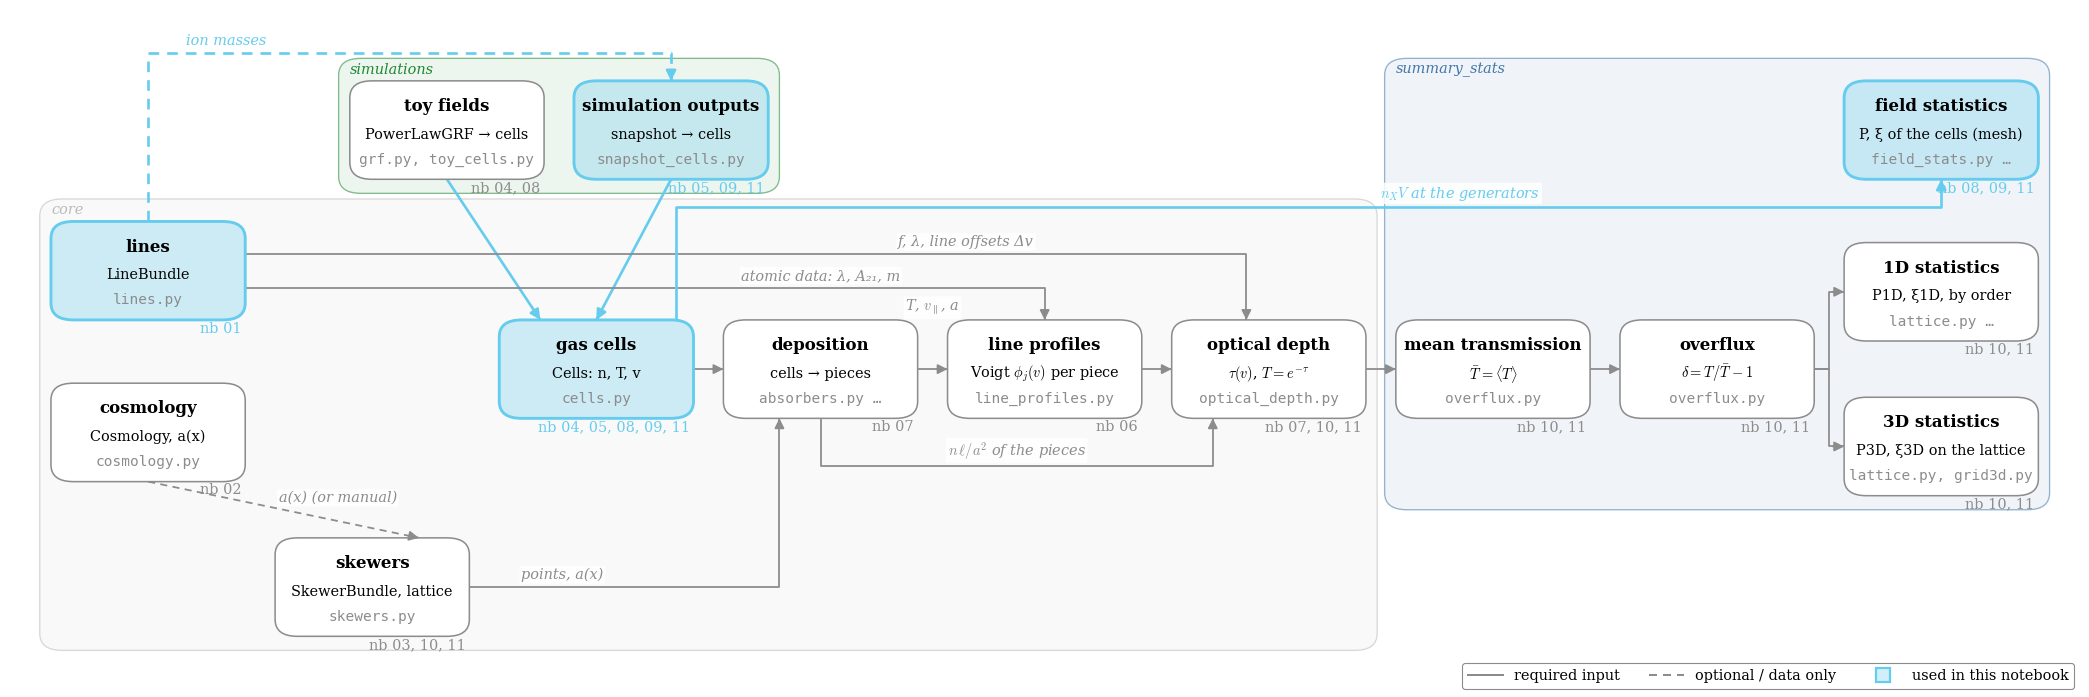

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import time
import numpy as np, jax
jax.config.update("jax_enable_x64", True)          # SkewerJAX follows this flag; it never sets it itself
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
# use_backend()                                    # interactive figures in a live notebook
use_style()
from skewerjax.utils.plotting import add_panel_letters, plot_dag
from skewerjax.core import LineBundle
from skewerjax.utils.paths import DATA_DIR as DATA      # folder with TNG50-4/: $SKEWERJAX_DATA (docs/installation.md)
plot_dag(("lines", "simulation", "fields", "field_stats")); plt.show()

In [2]:
from skewerjax.simulations import ArepoHDF5Reader
reader = ArepoHDF5Reader(f"{DATA}/TNG50-4", 25)          # the snapshot of notebooks 05, 07 and 11
H = reader.header
L = H.box_cMpc                                           # the box [cMpc]
LINE_IDS = ("HI-LyA", "SiIII-1206", "SiII-1193", "SiII-1190")   # the lines of 10 and 11: their species are the fields
LINES = LineBundle(list(LINE_IDS), ref_line_id=LINE_IDS[0])
FIELDS = (*LINES.species_keys, "gas")    # H I, Si III, Si II and the total gas (rho / m_u), the last drawn in black
N_MESH = 256                             # the mesh of the field statistics: H = L / N_MESH
MAS = "pcs"                              # mass assignment of the cells on the mesh (PCS: 4 nodes per axis)
INTERLACE = True                         # a second mesh shifted by H / 2 (the odd alias images cancel)
ENSEMBLE = "3 lines of sight (not independent)"
EACH = "each of the " + ENSEMBLE         # the legend of the faint curves
u = H.velfac_kms_per_cMpc                # aH [km/s per cMpc]: the shift v / (aH) of redshift space
print(f"TNG50-4 snapshot 25: z = {H.redshift:.4f}, a = {H.a:.5f}, box L = {L:.3f} cMpc, {H.n_gas:,} gas cells; u = aH = {u:.3f} km/s per cMpc")
print(f"fields: {FIELDS}; mesh {N_MESH}^3 of H = {L / N_MESH:.4f} cMpc, {MAS.upper()}, interlaced: {INTERLACE}")

TNG50-4 snapshot 25: z = 3.0081, a = 0.24949, box L = 51.668 cMpc, 19,250,411 gas cells; u = aH = 76.673 km/s per cMpc
fields: ('HI', 'SiIII', 'SiII', 'gas'); mesh 256^3 of H = 0.2018 cMpc, PCS, interlaced: True


**Cosmology.** The header holds $\Omega_m$, $\Omega_\Lambda$ and $h$; $\Omega_b$, $\sigma_8$ and $n_s$ come from the table of
IllustrisTNG (Planck 2015, `simulations.TNG_COSMOLOGY`). The sound horizon at the drag epoch from the fit of Aubourg et
al. 2015 (eq. 16), $r_d = 55.154\,e^{-72.3(\omega_\nu + 0.0006)^2}/(\omega_{cb}^{0.25351}\omega_b^{0.12807})$ Mpc with
$\omega_\nu = 0$, is the BAO scale $r_{\rm BAO}$ of notebooks 09 and 11. On the line of sight its images sit at
$\lvert r_d - nL\rvert$, folded into $[0, L/2]$.

In [3]:
from skewerjax.core import sound_horizon_drag
from skewerjax.simulations import TNG_COSMOLOGY as TNG
from skewerjax.utils.plotting import fold_periodic
for name, hv, tv in (("Omega_m", H.omega_m, TNG["Omega_m"]), ("Omega_Lambda", H.omega_l, TNG["Omega_Lambda"]), ("h", H.h, TNG["h"])):
    print(f"{name:>12}: header {hv:.4f}, IllustrisTNG {tv:.4f}, |difference| {abs(hv - tv):.1e}")
print("from the IllustrisTNG table (not in the header): " + ", ".join(f"{k} = {TNG[k]}" for k in ("Omega_b", "sigma_8", "n_s")))
w_b, w_cb = TNG["Omega_b"] * H.h**2, H.omega_m * H.h**2
R_BAO = float(sound_horizon_drag(w_b, w_cb))              # r_d [Mpc], comoving (Aubourg et al. 2015, eq. 16)
n_img = np.arange(-4, 5)
LOS_BAO = np.unique(np.round(fold_periodic(R_BAO - n_img * L, L), 3))
print(f"omega_b = {w_b:.5f}, omega_cb = {w_cb:.5f}: r_d = {R_BAO:.2f} cMpc = {R_BAO * H.h:.2f} h^-1 cMpc = {R_BAO / L:.3f} L; L / 2 = {L / 2:.2f} cMpc")
print(f"on the line of sight the images |r_d - n L| folded into [0, L / 2]: {LOS_BAO} cMpc")

     Omega_m: header 0.3089, IllustrisTNG 0.3089, |difference| 0.0e+00
Omega_Lambda: header 0.6911, IllustrisTNG 0.6911, |difference| 0.0e+00
           h: header 0.6774, IllustrisTNG 0.6774, |difference| 0.0e+00
from the IllustrisTNG table (not in the header): Omega_b = 0.0486, sigma_8 = 0.8159, n_s = 0.9667
omega_b = 0.02230, omega_cb = 0.14175: r_d = 147.30 cMpc = 99.78 h^-1 cMpc = 2.851 L; L / 2 = 25.83 cMpc
on the line of sight the images |r_d - n L| folded into [0, L / 2]: [7.706] cMpc


## Part A — The cells of TNG50-4 and their statistics

Every cell of the snapshot is read once and turned into `core.Cells` (`select_cells_in_region`, `gas_to_cells`, the
default `ExtractionOptions` of 05 and 07: H I stored, Si III and Si II from CLOUDY, the total gas `"gas"` as
$\rho/m_u$). The line of sight of the statistics is the second axis of the mesh (`los_axis=1`, as in 08): the cells of
each orientation have their coordinates permuted so that $x$, $y$ or $z$ becomes it.

In [4]:
from skewerjax.core import Cells, redshift_space_cells
from skewerjax.simulations import gas_to_cells, select_cells_in_region
t0 = time.perf_counter()
GAS = select_cells_in_region(reader, 0.0, L)                      # every cell of the snapshot (GasCells)
CELLS = gas_to_cells(GAS, FIELDS)                                 # -> core.Cells: per field n (comoving), T, v
del GAS
t_read = time.perf_counter() - t0
SWAP = {0: [1, 0, 2], 1: [0, 1, 2], 2: [0, 2, 1]}                 # axis a <-> y, the line of sight of the mesh


def los_along(cells, axis):
    # the cells seen with ``axis`` (0, 1, 2) as the line of sight: their generating points permuted (the field statistics
    # use the points, the volumes and the densities only)
    return Cells(np.asarray(cells.positions)[:, SWAP[axis]], cells.volumes, cells.species, cells.box, validate=False)


print(f"{len(CELLS):,} cells read and turned into core.Cells in {t_read:.1f} s; sizes V^(1/3) from {CELLS.size_cMpc.min():.3f} to "
      f"{CELLS.size_cMpc.max():.2f} cMpc (median {np.median(CELLS.size_cMpc):.3f})")
print("volume means [comoving cm^-3]: " + ", ".join(
      f"{f} {np.sum(CELLS.species[f]['number_density'] * CELLS.volumes) / L**3:.3e}" for f in FIELDS))

19,250,411 cells read and turned into core.Cells in 6.8 s; sizes V^(1/3) from 0.000 to 0.46 cMpc (median 0.160)
volume means [comoving cm^-3]: HI 3.009e-09, SiIII 1.456e-14, SiII 9.920e-15, gas 2.511e-07


### A1 · The bins

As in 08, the mesh fixes the ranges where a bin holds every direction: $\lvert\mathbf k\rvert$ from $2\pi/L$ to
$\pi/H$, $\lvert\mathbf r\rvert$ from $H$ to $L/2$. `K_EDGES`: one bin per mode up to $k_1$, then steps of half the
fundamental mode up to 1 cMpc$^{-1}$, then logarithmic bins (there is no BAO wiggle to resolve); `R_EDGES`: width $H$.
The trusted range of the mesh path (08) is printed with the statistics.

In [5]:
from skewerjax.summary_stats import bao_k_edges, box_grid
H_MESH = L / N_MESH
K_EDGES = bao_k_edges(2 * np.pi / L, np.pi / H_MESH, 1.0, k_1=None, dk_factor=0.5, n_log=16)
R_EDGES = np.arange(0, L / 2 + H_MESH, H_MESH)
GRID = box_grid(N_MESH, L, k_edges=K_EDGES, r_edges=R_EDGES)                  # the mesh and its bins (map rows: its own modes)
print(f"|k| bins: {K_EDGES.size - 1} from {K_EDGES[0]:.3f} to {K_EDGES[-1]:.2f} cMpc^-1; |r| bins: {R_EDGES.size - 1} of width {H_MESH:.4f} cMpc to L / 2")

|k| bins: 28 from 0.061 to 15.57 cMpc^-1; |r| bins: 128 of width 0.2018 cMpc to L / 2


### A2 · The fields in a plane

The section of the Voronoi cells by the plane $z = L/2$ (`voronoi_slice`: the cell of every pixel centre, no smoothing),
for each field: $x$ across, $y$ upwards; the bottom row shows the peculiar velocity along $y$ (colour) and $(v_x, v_y)$
(arrows), the same for every field (one gas).

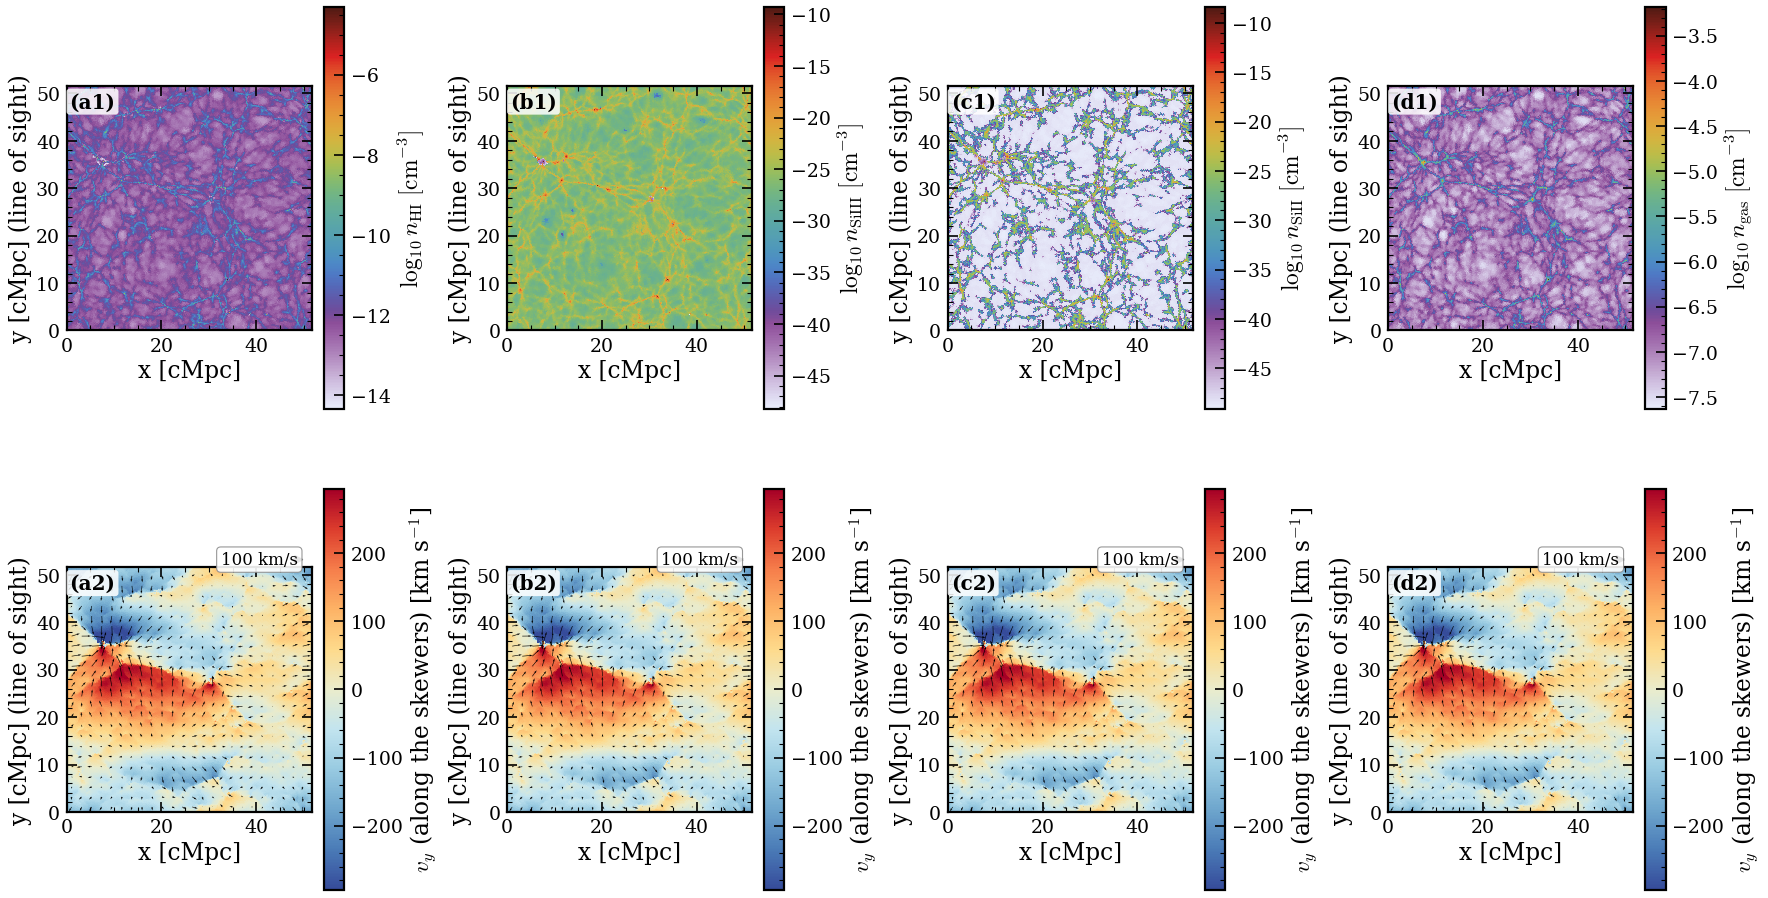

the plane z = 25.83 cMpc: 768,188 cells searched; velocity arrows: 100 km/s key


In [6]:
from skewerjax.simulations import voronoi_slice
from skewerjax.utils.plotting import plot_toy_fields
N_PIX_SLICE = 512
SL = {f: voronoi_slice(CELLS, f, 3, 0.5 * L, n_pix=N_PIX_SLICE) for f in FIELDS}
PLANE = dict(n={f: s["n"][:, :, None] for f, s in SL.items()}, v=SL["gas"]["v"][:, :, None, :])   # one layer: (N, N, 1)
fig, axs, info = plot_toy_fields(PLANE, L, z_index=0, centres="pixels", arrow_every=N_PIX_SLICE // 24, figsize=(22, 12))
add_panel_letters(axs.T.ravel(), labels=[f"{c}{r}" for c in "abcd" for r in (1, 2)])
plt.show()
print(f"the plane z = {0.5 * L:.2f} cMpc: {SL['gas']['n_cells']:,} cells searched; velocity arrows: {info['key_kms']:.0f} km/s key")

### A3 · The statistics, real space and redshift space

`field_statistics` on the cells of the three orientations (the ensemble): in real space the generating points as they
are; in redshift space moved along the line of sight by $v_\parallel/(aH)$ (`redshift_space_cells`, the plane-parallel
mapping of one snapshot, $u = aH$), wrapped into the box. The cells keep their volumes, so every cell carries its number
of particles $n_X V$ to its new place.

In [7]:
from skewerjax.summary_stats import field_statistics
t0 = time.perf_counter()
REAL = field_statistics((los_along(CELLS, a) for a in range(3)), GRID, species=FIELDS, mas=MAS, interlace=INTERLACE, log=None)
t_real = time.perf_counter() - t0
RSD = field_statistics((los_along(redshift_space_cells(CELLS, a, u), a) for a in range(3)), GRID, species=FIELDS, mas=MAS,
                       interlace=INTERLACE, log=None)
t_rsd = time.perf_counter() - t0 - t_real
TRUST = REAL["gas"]["trusted"]
print(f"real space {t_real:.0f} s, redshift space {t_rsd:.0f} s ({len(FIELDS)} fields x 3 orientations each, {len(CELLS):,} cells on {N_MESH}^3)")
print(f"trusted range of the mesh path (08): k < k_Nyq / 2 = {TRUST['k_max']:.2f} cMpc^-1, r >= 6 H = {TRUST['r_min']:.2f} cMpc")
a0 = REAL["gas"]["axes"]
lo = np.flatnonzero(np.isfinite(REAL["gas"]["P_iso"]))[:4]
print("P_X / P_gas in the first |k| bins (real space; b_X^2 on large scales): " + "; ".join(
      f"{f} {np.round(REAL[f]['P_iso'][lo] / REAL['gas']['P_iso'][lo], 2)}" for f in FIELDS[:-1]))
print("P(redshift space) / P(real space) in the same bins: " + "; ".join(f"{f} {np.round(RSD[f]['P_iso'][lo] / REAL[f]['P_iso'][lo], 2)}" for f in FIELDS))

real space 90 s, redshift space 137 s (4 fields x 3 orientations each, 19,250,411 cells on 256^3)
trusted range of the mesh path (08): k < k_Nyq / 2 = 7.78 cMpc^-1, r >= 6 H = 1.21 cMpc
P_X / P_gas in the first |k| bins (real space; b_X^2 on large scales): HI [ 9.23  9.26 12.03 11.84]; SiIII [21.37 25.14 36.24 35.36]; SiII [13.67 13.34 19.32 17.88]
P(redshift space) / P(real space) in the same bins: HI [1.17 1.11 1.07 0.96]; SiIII [1.08 0.98 0.92 0.75]; SiII [1.13 1.07 1.02 0.92]; gas [1.75 1.68 1.71 1.66]


**$P(\lvert\mathbf k\rvert)$ and $r^2\xi(\lvert\mathbf r\rvert)$ of the four fields.** Real space, then redshift space:
every orientation faint, their mean with the error of the mean as points; the limits of the mesh shaded. The species
follow the gas with very different amplitudes: H I and the metal ions sit in the densest cells.

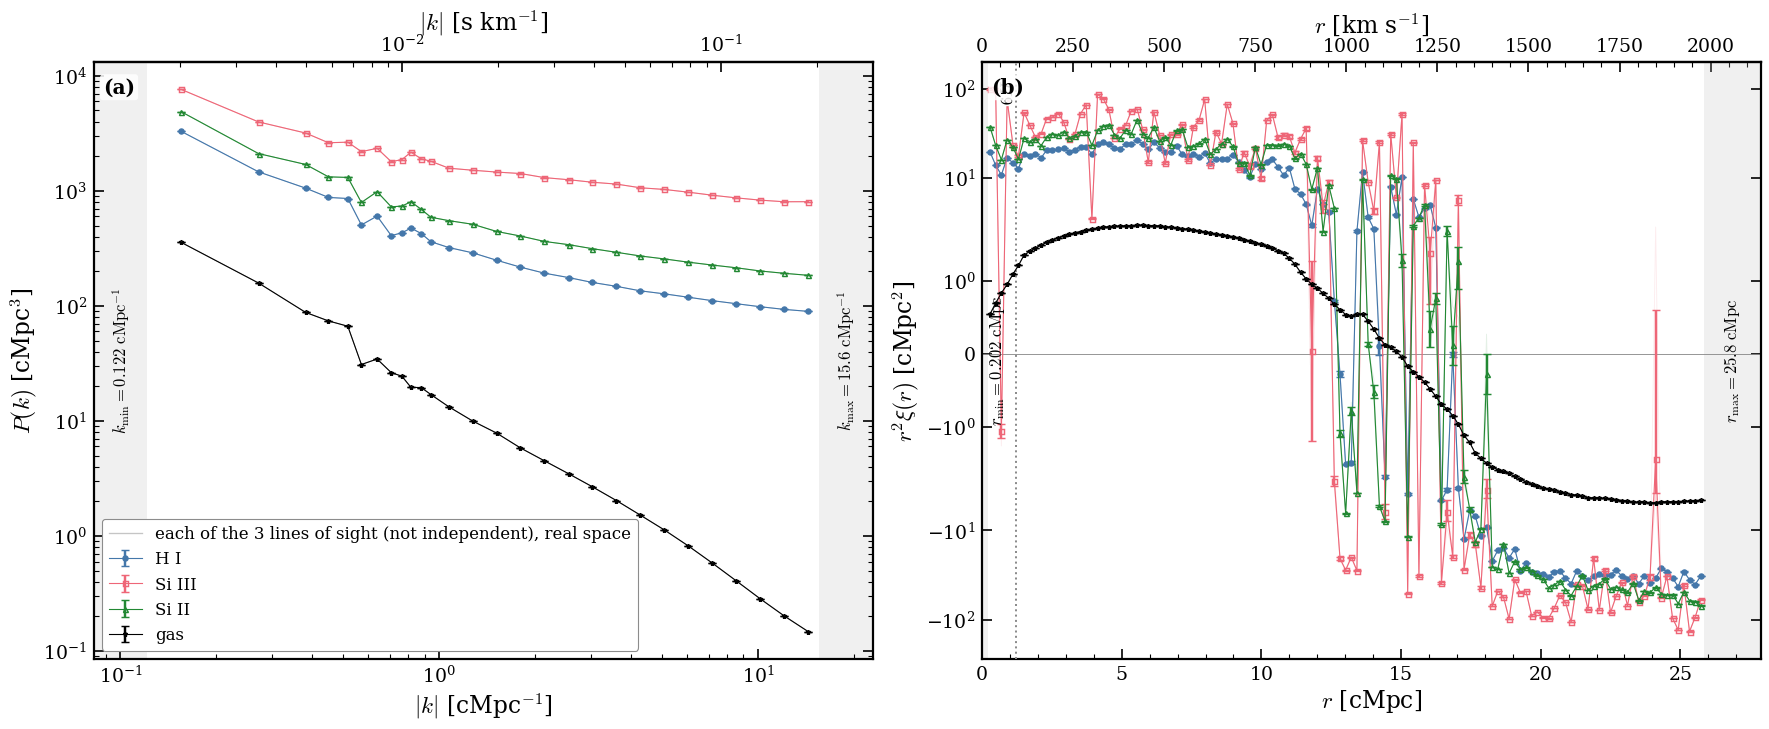

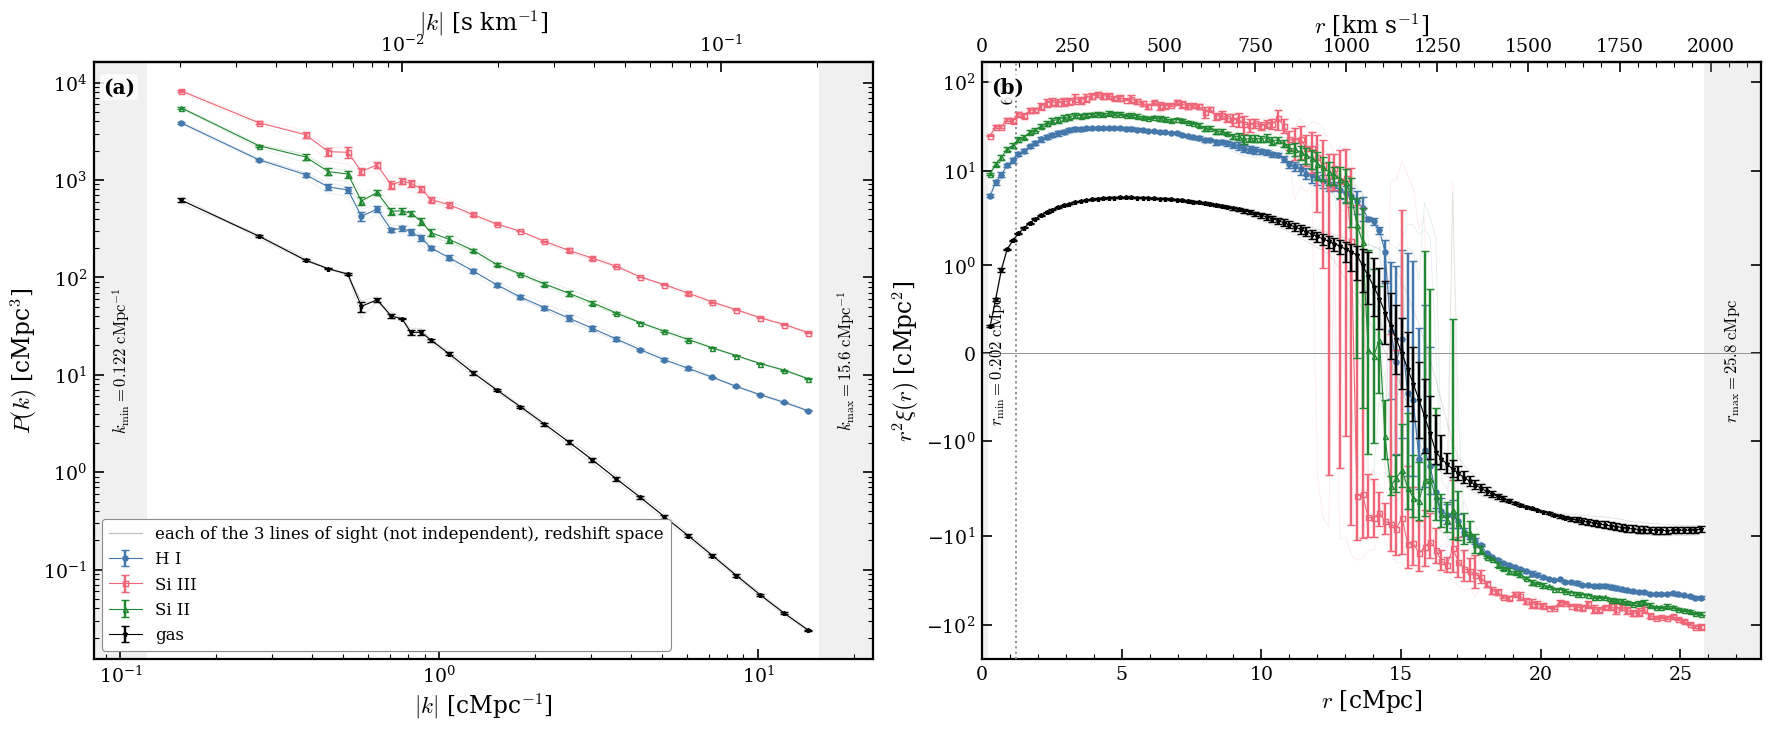

In [8]:
from skewerjax.utils.plotting import field_names, plot_overflux_3d
NAMES = field_names(FIELDS, LINE_IDS)
MARKS = {r"$6H$": TRUST["r_min"]}
for res, space in ((REAL, "real space"), (RSD, "redshift space")):
    fig, axs = plot_overflux_3d({f: res[f] for f in FIELDS}, res["gas"]["axes"], kms_per_cMpc=u, r_marks=MARKS, names=NAMES,
                                k_edges=K_EDGES, r_edges=R_EDGES, limits=res["gas"]["limits"], quantity="r2xi", y_scale="symlog",
                                each_label=EACH + ", " + space)
    add_panel_letters([axs["P"], axs["xi"]])
    plt.show()

**The total gas, as in 08 (A3).** The figure of 08 without its expectation (there is none) and without the residual row:
$P$ against $\lvert\mathbf k\rvert$ with the transitions of the bins and the trusted range, $r^2\xi$ against
$\lvert\mathbf r\rvert$, real space.

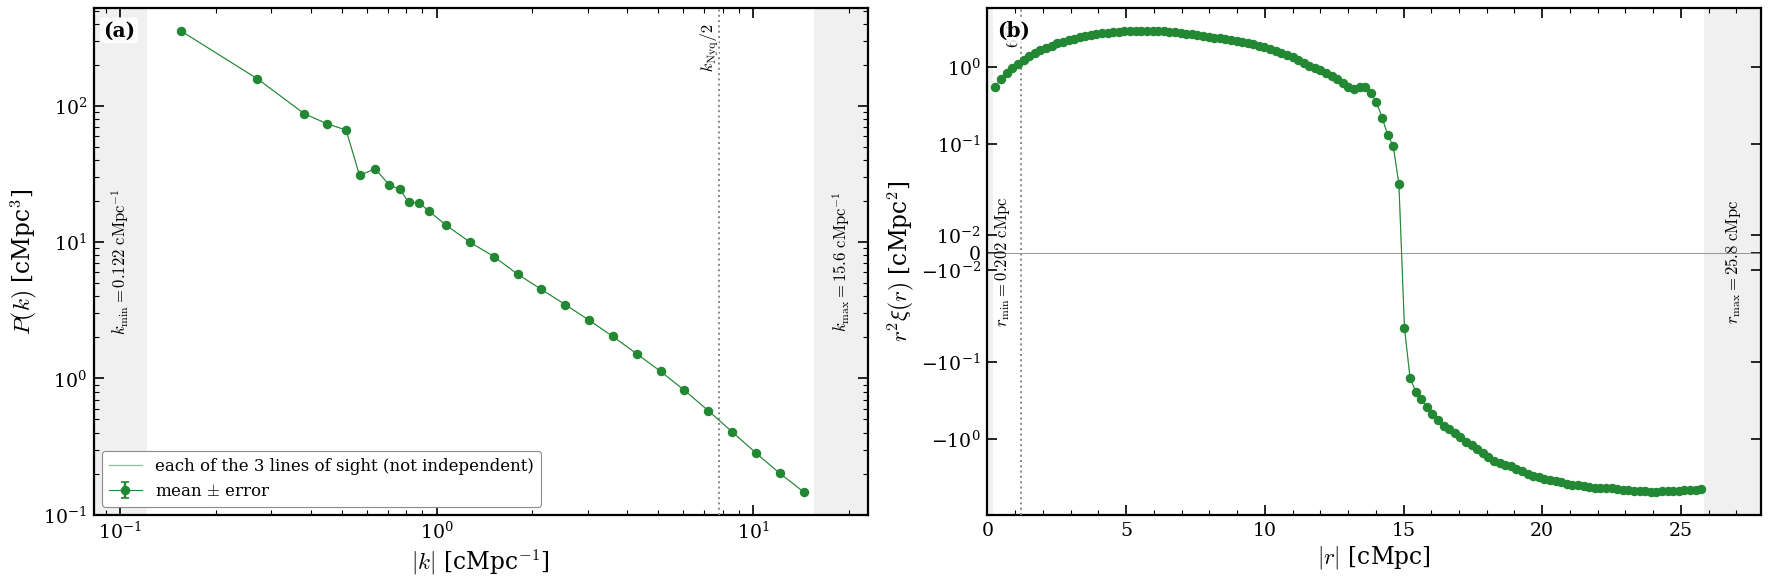

In [9]:
from skewerjax.utils.plotting import plot_isotropic_recovery
K_MARKS = {r"$k_{\rm Nyq}/2$": TRUST["k_max"]}
fig, axs, rec = plot_isotropic_recovery(REAL["gas"], quantity="r2xi", k_edges=K_EDGES, r_edges=R_EDGES, k_marks=K_MARKS, r_marks=MARKS,
                                        y_scale="symlog", k_scale="log", each_label=EACH)
add_panel_letters(axs[0])
plt.show()

**The $(k_\perp, k_\parallel)$ and $(r_\perp, r_\parallel)$ planes and the wedges of $\mu$, in redshift space** (the
gas): the counterparts of 08's maps, measured only. Along the line of sight the peculiar velocities stretch and squeeze
the field (the Kaiser and Finger-of-God effects), so the maps are no longer isotropic; in real space they are (printed:
the wedges against their mean). The BAO ring, $r_d > L/2$, enters through its periodic images about $(0, nL)$: the
dotted arcs of the map and the dotted lines of the wedges ($n_\perp = 0$; the images across the line of sight are
smeared by the average over $r_\perp$).

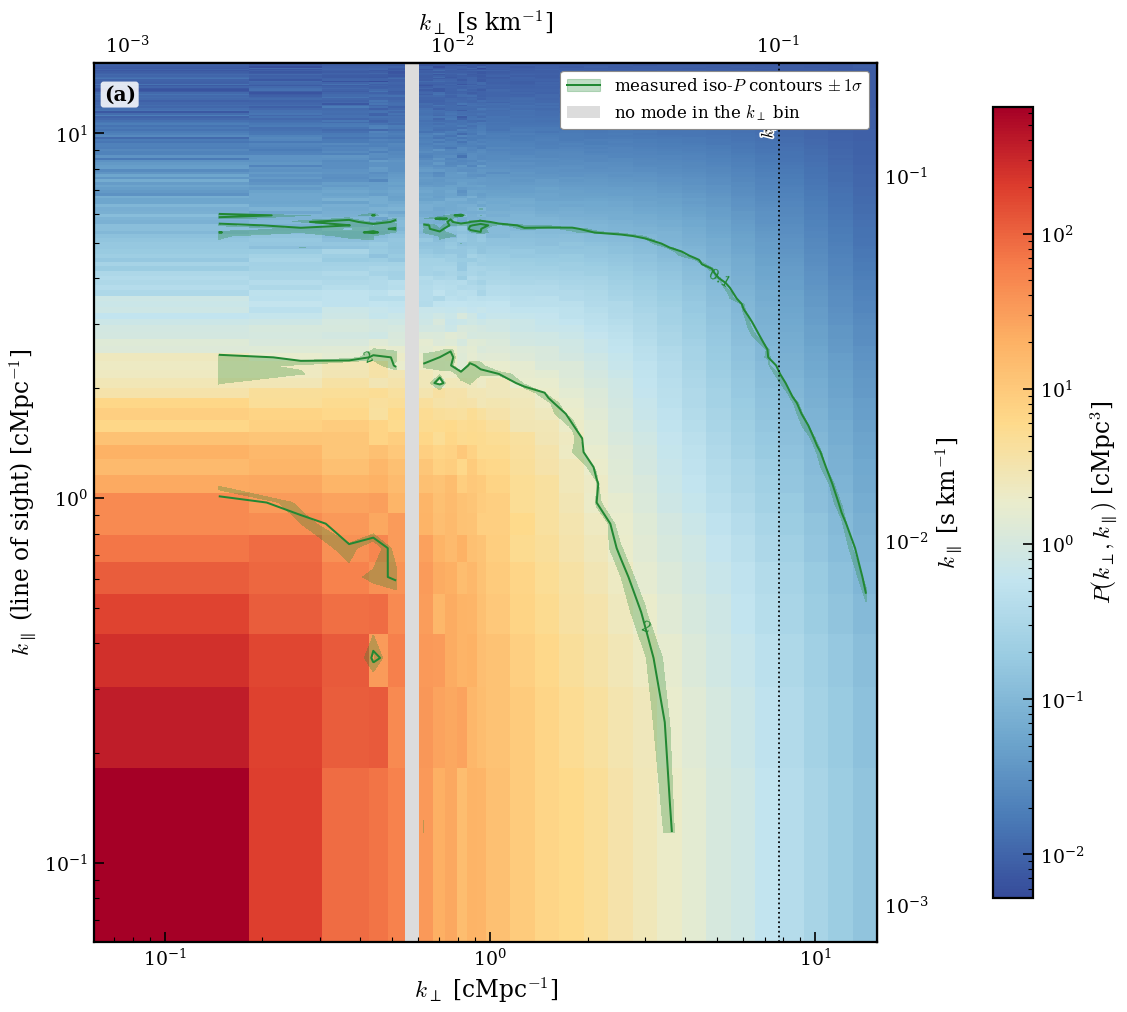

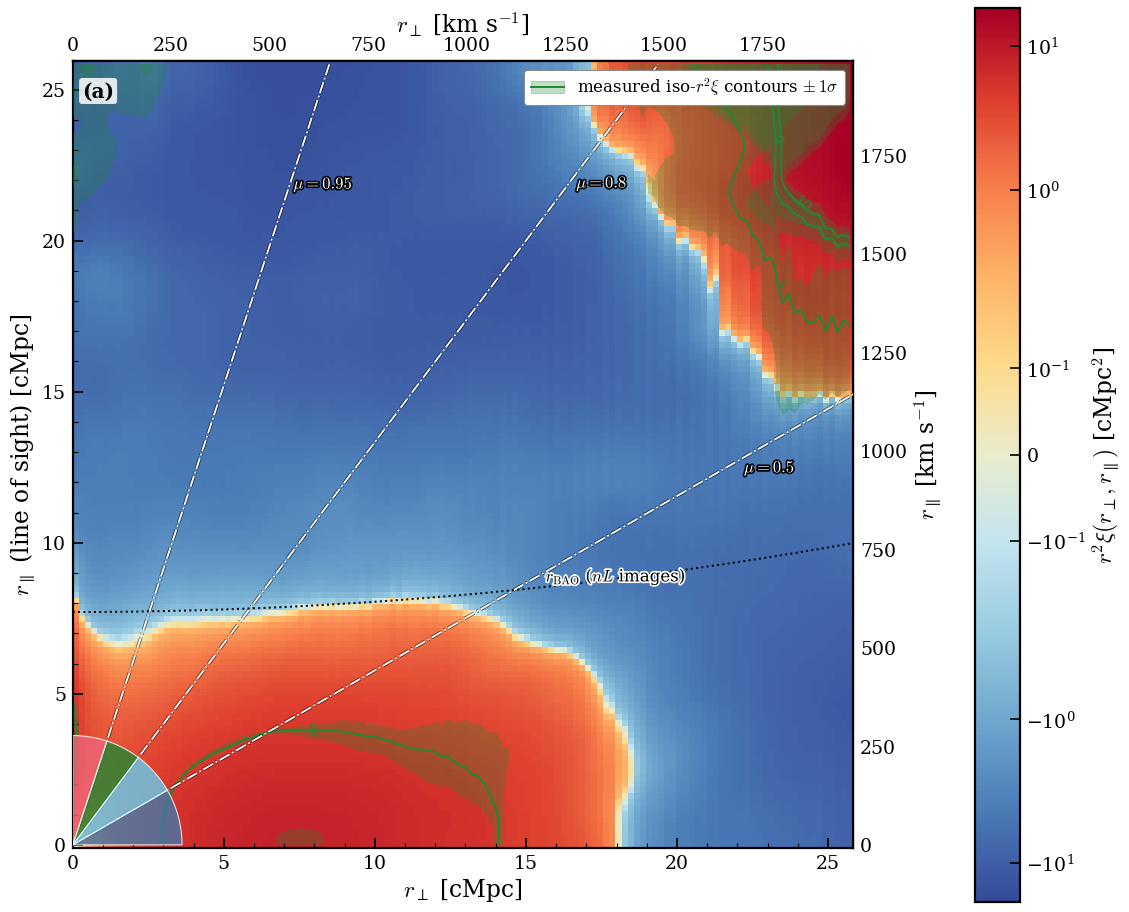

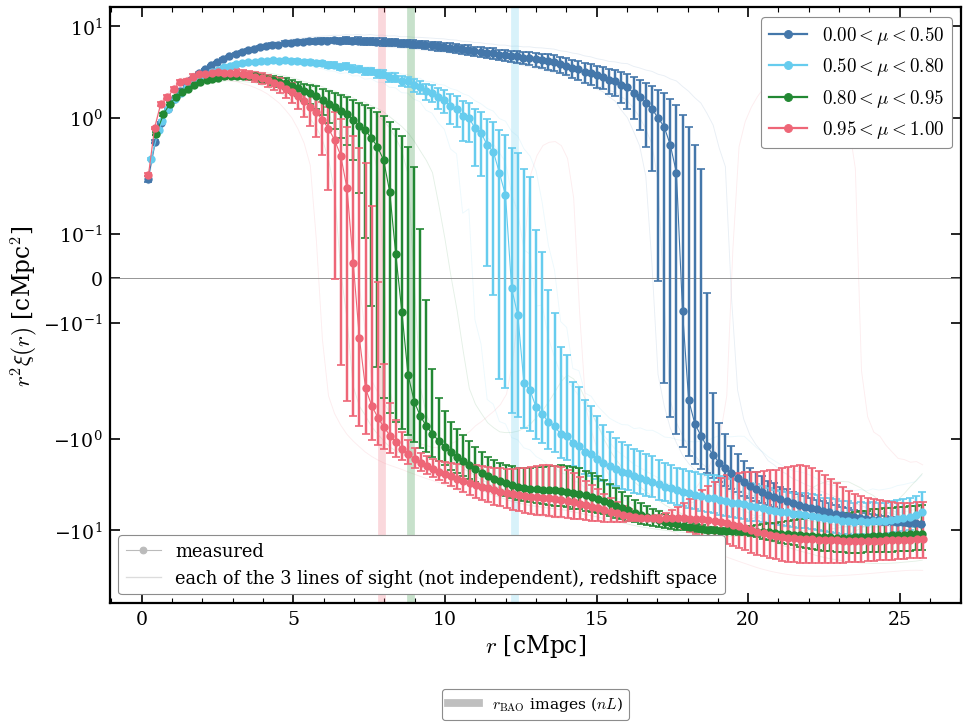

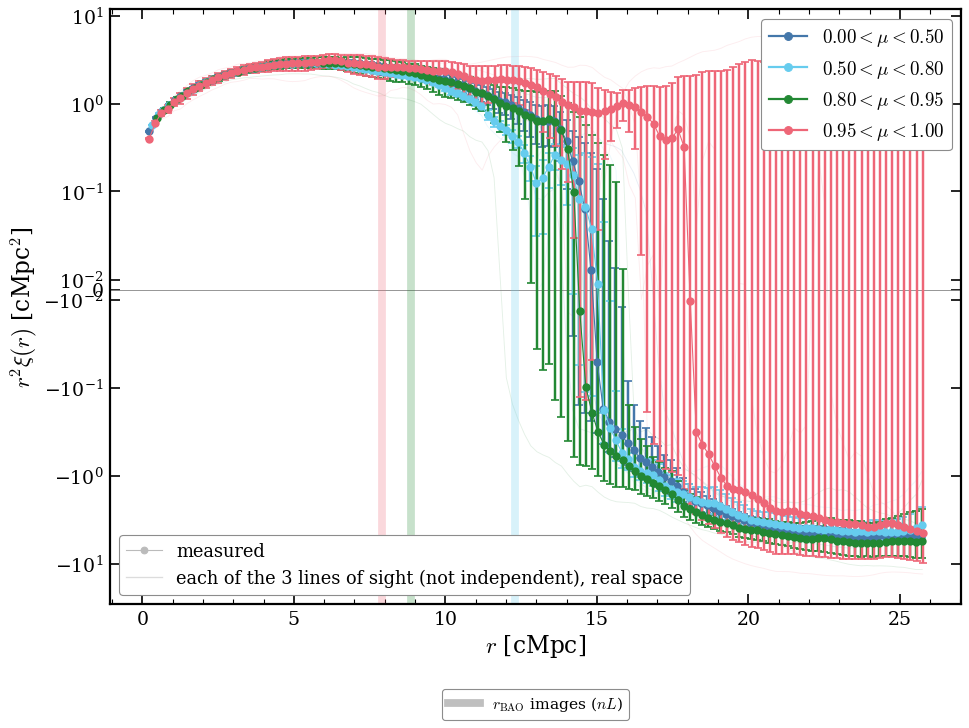

real space: xi of the gas in the wedges / their mean over r >= 6 H (median over r): 0.00-0.50: 1.000, 0.50-0.80: 0.955, 0.80-0.95: 1.007, 0.95-1.00: 1.007
redshift space: xi of the gas in the wedges / their mean over r >= 6 H (median over r): 0.00-0.50: 0.718, 0.50-0.80: 0.771, 0.80-0.95: 1.183, 0.95-1.00: 1.302
r_BAO = r_d = 147.3 cMpc; its images on the line of sight at [7.706] cMpc (folded into [0, L / 2])


In [10]:
from skewerjax.utils.plotting import plot_kpar_kperp_maps, plot_rpar_rperp_maps, plot_xi_mu_wedges
figs, axs, _ = plot_kpar_kperp_maps(RSD["gas"], kperp_edges=K_EDGES, n_sigma=1, k_marks=K_MARKS, kpar_scale="log", kperp_scale="log", kms_per_cMpc=u)
add_panel_letters(axs)
plt.show()
figs, axs, _ = plot_rpar_rperp_maps(RSD["gas"], rperp_edges=R_EDGES, r_bao=R_BAO, n_sigma=1, quantity="r2xi", color_scale="symlog", kms_per_cMpc=u)
add_panel_letters(axs)
plt.show()
for res, space in ((RSD, "redshift space"), (REAL, "real space")):
    fig, axs, _ = plot_xi_mu_wedges(res["gas"], r_edges=R_EDGES, r_bao=R_BAO, box=L, quantity="r2xi", y_scale="symlog", each_label=EACH + ", " + space)
    plt.show()
a = RSD["gas"]["axes"]
ok = (a["r_mu"] >= TRUST["r_min"]) & (a["r_mu"] <= 0.5 * L)
for res, space in ((REAL, "real space"), (RSD, "redshift space")):
    X = np.where(ok, res["gas"]["xi_mu"], np.nan)
    n_ok = np.sum(np.isfinite(X), axis=0)
    m = np.where(n_ok > 0, np.nansum(X, axis=0) / np.maximum(n_ok, 1), np.nan)   # the mean over the wedges at each |r|
    print(f"{space}: xi of the gas in the wedges / their mean over r >= 6 H (median over r): " + ", ".join(
          f"{a['mu_edges'][w]:.2f}-{a['mu_edges'][w + 1]:.2f}: {np.nanmedian(X[w] / m):.3f}" for w in range(X.shape[0])))
print(f"r_BAO = r_d = {R_BAO:.1f} cMpc; its images on the line of sight at {LOS_BAO} cMpc (folded into [0, L / 2])")